In [1]:
import torch
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cpu


In [2]:
transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="data", train=True, download=True, transform=transform
)

test_data = datasets.FashionMNIST(
    root="data", train=False, download=True, transform=transform
)

print("Training images:", len(train_data))
print("Test images:", len(test_data))

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 308kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.59MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 8.59MB/s]

Training images: 60000
Test images: 10000


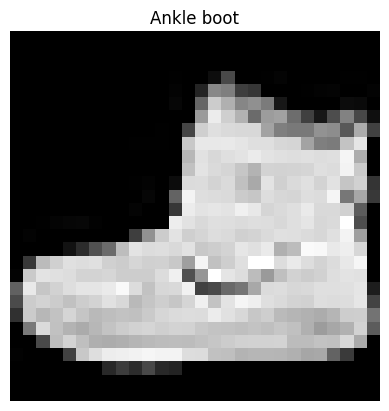

In [3]:
import matplotlib.pyplot as plt

image, label = train_data[0]

plt.imshow(image.squeeze(0), cmap="gray")
plt.title(train_data.classes[label])
plt.axis("off")
plt.show()

In [4]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

In [5]:
from torch import nn

model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
).to(device)

print(model)

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=64, bias=True)
  (8): ReLU()
  (9): Linear(in_features=64, out_features=10, bias=True)
)


In [6]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

model.train()
for epoch in range(3):
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        scores = model(images)
        loss = loss_fn(scores, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_data)
    print(f"Epoch {epoch + 1}/3 — Training loss: {average_loss:.4f}")

Epoch 1/3 — Training loss: 0.5457
Epoch 2/3 — Training loss: 0.3506
Epoch 3/3 — Training loss: 0.3034


In [7]:
model.eval()
correct = 0

with torch.no_grad():
    for images, labels in test_loader:
        scores = model(images.to(device))
        predictions = scores.argmax(dim=1)
        correct += (predictions == labels.to(device)).sum().item()

accuracy = correct / len(test_data)
print(f"Test accuracy: {accuracy:.2%}")

Test accuracy: 87.33%


In [8]:
from google.colab import files

torch.save(model.state_dict(), "fashion_cnn.pth")
files.download("fashion_cnn.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>